<a href="https://colab.research.google.com/github/MarkAntonio/Classificador-Fake-News-Pre-Processed-by-Text/blob/main/classificador_fake_news_pre_processed_by_text.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Atividade**: Construir um classificador de notícias falsas usando os conceitos que vimos na aula passada. O modelo deve seguir a mesma ideia do modelo de classificação de sentimentos visto em sala. Porém, o que irá mudar é que agora vocês irão construir um modelo treinado com um novo dataset. A ideia é que vocês construam o melhor classificador possível, registrando a evolução dele, em termos de acurácia, a cada melhoria que vocês implementem no projeto, documentando quais melhorias realmente tornaram a classificação dos documentos mais acurada. O dataset que vocês deverão utilizar será adicionado na atividade lá no Classroom.

Para ajudá-los a lembrar dos conceitos, neste notebook, eu também adicionei as etapas e descrições do que implementei em sala com vocês, como:

**1. carregamento do dataset;**

**2. divisão dos conjuntos de treino/teste;**

**3. construção dos vetorizadores e transformação dos dados em suas formas vetorizadas;**

**4. Treinamento de um modelo de aprendizado de máquina;**

**5. avaliação do modelo treinado.**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Etapa 1 - Leitura do dataset**

Aqui, nós utilizamos em sala a biblioteca do pandas para o carregamento dos dados. Vocês podem instalar o pandas (e qualquer outra lib) usando o pip do python.

In [ ]:
#código python aqui
import pandas
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB

from sklearn import metrics

import matplotlib.pyplot as plt
import nltk
import seaborn as sns

%matplotlib inline



**Etapa 2 - Divisão dos conjuntos de trenio/teste**

Nesta etapa, eu utilizei a função train_test_split do sklearn. Lembrem que ela nos permite, de forma bem simples, quebrar os dados nos conjuntos de treino e teste. Inclusive, podemos especificar a proporção destes conjuntos. Uma sugestão é que vocês comecem com uma proporção de 70% para treino e 30% para teste. Mas isso é só uma sugestão! Vocês deverão encontrar a melhor proporção para o modelo treinado.

In [ ]:
# Importando o arquivo com o pandas
fn_df = pandas.read_csv("/content/drive/MyDrive/Tópicos Avançados em IA/dataset_fn.csv")




In [ ]:
# concatenando as colunas titulo e texto
fn_df['news'] = fn_df['title'] + ' ' + fn_df['text']

In [ ]:

# tranformando as classificações FAKE e REAL, respectivamente, em 0 e 1 (binário)
labels = []

for classif in fn_df['label']:
  if classif == "REAL":
    labels.append(1)
  else:
    labels.append(0)

fn_df['label'] = labels

In [ ]:
# Pré-processamento do texto
"""
Deixar tudo em minúsculo
Filtrar apenas letras
Remover stopwords
Lematizar
"""

# importando a lista de stopwords da nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stopwords = stopwords.words("english")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
# baixando o modelo do lematizador
!spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 73.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# importando o modelo
import en_core_web_sm

spc = en_core_web_sm.load()

In [ ]:
# função do pré-processamento do texto
import re

def limpa_texto(texto):

  texto = texto.lower()
  """
  re.sub(r"[\W\d_]+", " ", texto): A função re.sub vai procurar todas as ocorrências de um ou
  mais caracteres que não são letras alfabéticas, dígitos ou sublinhados
   no texto e substituir por um espaço em branco.


   - \W: Todos os caracteres que não são alfanuméricos (ou seja, não letras nem números).
   - \d: Todos os dígitos numéricos (0-9).
   - _: O caractere de sublinhado (underscore).

  """
  texto = re.sub(r"[\W\d_]+", " ", texto)


  texto = [palavra for palavra in texto.split() if palavra not in stopwords]

  spc_texto = spc(" ".join(texto))

  """
  Verifica se o lema da palavra não é "-PRON-" (PRONOME).
  Se o lema da palavra for -PRON-, em vez de lematizar, ele usa a palavra na
  forma minúscula (lower_), pois pronomes geralmente não têm uma lematização adequada.
  """
  tokens = [word.lemma_ if word.lemma_ != "-PRON-" else word.lower_ for word in spc_texto]

  return " ".join(tokens)

# Aplica a funcao nas reviews do dataset
fn_df['news'] = fn_df['news'].apply(limpa_texto)

In [ ]:
coun_vec = CountVectorizer()

vec = CountVectorizer(binary=True)
texto = fn_df["news"]

X_bow = vec.fit_transform(texto)

**Etapa 3 - Construção dos vetorizadores**

Em sala, nós utilizamos o CountVectorizer e o TfidfVectorizer também do sklearn. Aqui vocês podem e devem brincar à vontade com estes vetorizadores para descobrir qual produz, no final, os melhores resultados.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vect = TfidfVectorizer()
X_tfidf = tfidf_vect.fit_transform(texto)


In [ ]:
# Com o count vectorizer
X1_train, X1_test, y1_train, y1_test = train_test_split(X_bow, fn_df['label'],
                                                        test_size=0.3, random_state = 13)
# Com o TfidfVectorizer
X2_train, X2_test, y2_train, y2_test = train_test_split(X_tfidf, fn_df['label'],
                                                        test_size=0.3, random_state = 13)







**Etapa 4 - Treinamento de um modelo de aprendizado de máquina**

Com os dados devidamente preparados, podemos agora fornecê-los a algum modelo de Machine Learning para que ele "se vire" para aprender os padrões presentes nos dados e aprenda a classificá-los de acordo com os labels (rótulos) presentes nos dados. Estes labels indicarão se uma notícia é FALSA ou REAL. Novamente, vocês podem usar os modelos já existentes no sklearn. E não precisam se limitar à modelos de ML tradicionais. Podem usar redes neurais também, pois o sklearn tem uma implementações deste tipo também. O modelo que usei em sala foi o MultinomialNB, que é bem limitado (vocês podem e devem encontrar uma opção melhor).

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score

def mostra_metricas(y_true, y_pred):
  ''' Função que recebe o y real, o y predito e mostra as
  principais metricas.
  '''
  print("Acurácia: ", accuracy_score(y_true, y_pred))
  print("\nAUROC:", roc_auc_score(y_true, y_pred))
  print("\nF1-Score:", f1_score(y_true, y_pred, average='weighted'))
  print("\nMatriz de confusão:")
  sns.heatmap(confusion_matrix(y_true, y_pred), annot=True)
  plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
# modelo de regressão logistica com o texto convertido através do Count Vectorize
reglog = LogisticRegression()
reglog.fit(X1_train, y1_train)

y1_reglog_pred = reglog.predict(X1_test)

In [ ]:
# modelo de regressão logistica com o texto convertido através do TFIDFVectorize
reglog2=LogisticRegression()
reglog2.fit(X2_train, y2_train)

y2_reglog_pred = reglog2.predict(X2_test)

In [ ]:
# modelo de Multinomial Naive Bayes com o texto convertido através do Count Vectorize

mnb = MultinomialNB()

mnb.fit(X1_train, y1_train)
y3_mnb_pred = mnb.predict(X1_test)

In [ ]:
# modelo de Multinomial Naive Bayes com o texto convertido através do TFIDFVectorize

mnb2 = MultinomialNB()

mnb2.fit(X2_train, y2_train)
y2_mnb_pred = mnb2.predict(X2_test)

Acurácia:  0.9405576012624934

AUROC: 0.940574655133862

F1-Score: 0.9405584237212239

Matriz de confusão:


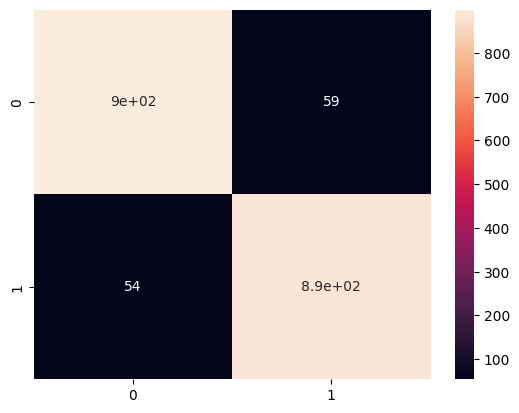

In [ ]:
# modelo de Multi-layer Perceptron classifier com o texto convertido através do TFIDFVectorize
# O MELHOR!! dentre os outros

from sklearn.neural_network import MLPClassifier


'''
Cria uma rede neural (MLPClassifier) com uma única camada oculta contendo 70 neurônios.
Usa o otimizador LBFGS para ajustar os pesos.
A regularização L2 é configurada para um valor leve com alpha=1e-5.
A execução será reprodutível graças ao random_state=1.
O treinamento do modelo imprimirá informações detalhadas devido ao verbose=True.
'''
mlpc = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(70, ), random_state=1, verbose=True)

mlpc.fit(X2_train, y2_train)
y_mlpc_pedict = mlpc.predict(X2_test)




**Etapa 5 - Avaliação do modelo treinado**

Por fim, vocês devem avaliar o modelo treinado, comparando as predições que ele fez com os dados de teste. No exemplo feito em sala, eu usei a acurácia como métrica de avaliação. Vocês podem usar outras métricas também.

Acurácia:  0.5102577590741715

AUROC: 0.5102425625029098

F1-Score: 0.5104380726977783

Matriz de confusão:


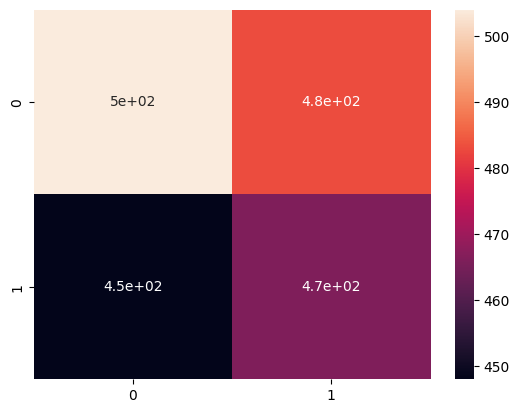

In [ ]:
# Regressão logistica + CountVectorizer
mostra_metricas(y1_test, y1_reglog_pred)

Acurácia:  0.9216201998947923

AUROC: 0.9214036179120073

F1-Score: 0.9215471065502049

Matriz de confusão:


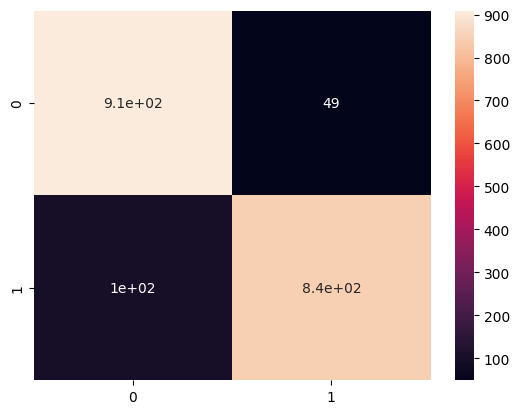

In [ ]:
# Regressão logistica + TFIDFVectorizer
mostra_metricas(y2_test, y2_reglog_pred)

Acurácia:  0.9005786428195687

AUROC: 0.9009751005652018

F1-Score: 0.9003594078337303

Matriz de confusão:


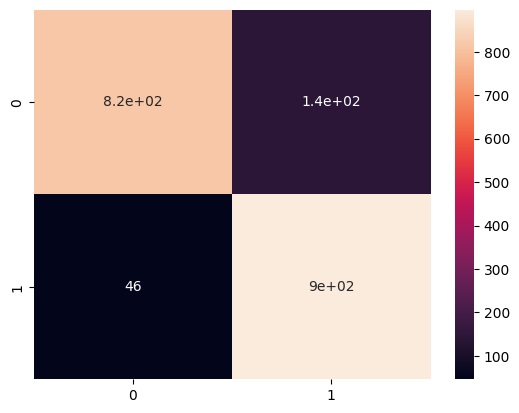

In [ ]:
# Multinomial Nayve Bayes + CountVectorizer
mostra_metricas(y1_test, y3_mnb_pred)

Acurácia:  0.8290373487638085

AUROC: 0.8302761585753281

F1-Score: 0.8248704546641913

Matriz de confusão:


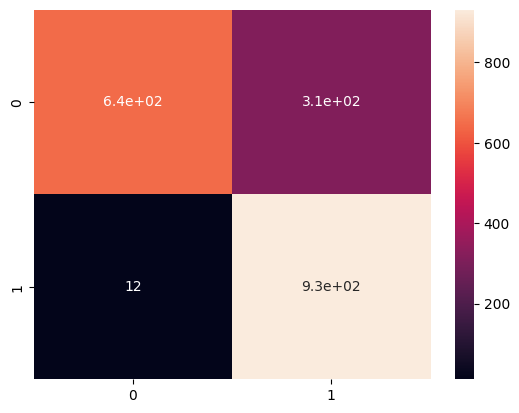

In [ ]:
# # Multinomial Nayve Bayes + TFIDFVectorizer
mostra_metricas(y2_test, y2_mnb_pred)

In [ ]:
# Multi-layer Perceptron Classifier + TFIDFVectorizer
mostra_metricas(y2_test, y_mlpc_pedict)